### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# for Checking Random Walk
from statsmodels.tsa.stattools import adfuller

In [4]:
# For Prediction
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf, plot_predict

In [5]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [6]:
# Custom module
from TimeSeriesCustFunc import *

__SARIMAX_Graph__(`data`, `col`, `pred`, `time_range`, `title`, `xlabel, ylabel`, `legend=['Observed', 'Predicted']`)
* __SARIMAX_Graph__(`data`, `col_to_pred`, `[pred, pred_ci]`, `[time_range_for_Observation, time_range_for_Prediction]`, `title_of_plot`, `xlabel`, `ylabel`, `[legend_for_Observation, legend_for_Prediction]`)

__Run_SARIMAX__(`data`, `mod_order`, `time_range`, `col`, `season_order=(0,0,0,0)`, `title=''`, `xlabel=''`, `ylabel=''`)
* __Run_SARIMAX__(`data`, `(p, d, q)`, `[time_range_for_Observation, time_range_for_Prediction]`, `col_to_pred`, `(P, D, Q, m)`, `title_of_plot`, `xlabel`, `ylabel`)
* return model

__AIC_BIC_withOrderRange__(`data`, `p=1`, `d=1`, `q=1`, `P=1`, `D=1`, `Q=1`, `m=1`)
* Compute accuracy with AIC, BIC
* p, d, q, P, D, Q, m must be greater than 0
* return AIC, BIC

__LoadClean_wfp_food_prices_mmr()__
* Load wfp_food_prices_mmr(Cleaned).csv and clean the data
* return DF

### Set Global Variables

In [7]:
obv_st_date = pd.to_datetime("2008-01-01")
obv_end_date = pd.to_datetime("2022-02-01")
pred_st_date = pd.to_datetime("2019-01-01")
pred_end_date = pd.to_datetime("2025-01-01")

### Loading and Cleaning data

In [8]:
data = LoadClean_wfp_food_prices_mmr()
data.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [9]:
data.shape

(31972, 14)

In [10]:
data.isnull().sum()

date                   0
region                 0
city                   0
market                 0
category               0
commodity              0
Exact Commodity        0
Quality            25706
unit                   0
priceflag              0
pricetype              0
currency               0
price                  0
usdprice               0
dtype: int64

### Preparing for Prediction

In [11]:
DCTM_Y = data.copy()
mask = (DCTM_Y['category']=='cereals and tubers') & (DCTM_Y['region']=='Yangon')
DCTM_Y = DCTM_Y.loc[mask]
DCTM_Y.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
4079,1/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,10 KG,actual,Retail,MMK,845.00,0.4747
4080,1/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,KG,actual,Wholesale,MMK,307.76,0.1729
4334,2/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,10 KG,actual,Retail,MMK,865.01,0.4860
4335,2/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,KG,actual,Wholesale,MMK,328.66,0.1846
4610,3/15/2011,Yangon,Yangon (West),Yangon,cereals and tubers,Rice (Emata),Emata,NaN,10 KG,actual,Retail,MMK,888.24,0.4990


In [12]:
DCTM_Y = DCTM_Y[['date', 'price']]
DCTM_Y['date'] = pd.to_datetime(DCTM_Y['date'])
mask = (DCTM_Y['date']>=obv_st_date) & (DCTM_Y['date']<=obv_end_date)
DCTM_Y = DCTM_Y.loc[mask]
DCTM_Y = DCTM_Y.set_index('date')
DCTM_Y.head()

,price
date,
2011-01-15,845.00
2011-01-15,307.76
2011-02-15,865.01
2011-02-15,328.66
2011-03-15,888.24


In [13]:
DCTM_Y = DCTM_Y.resample('MS').mean()
DCTM_Y.head()

,price
date,
2011-01-01,576.380
2011-02-01,596.835
2011-03-01,618.900
2011-04-01,615.000
2011-05-01,622.470


In [14]:
DCTM_Y.shape

(133, 1)

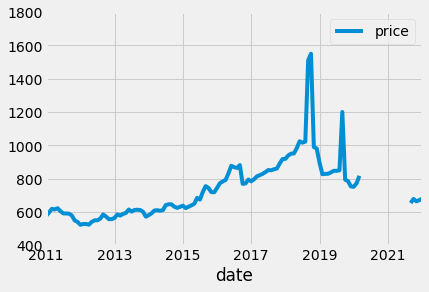

In [15]:
DCTM_Y.plot(grid=True)
plt.show()

It has upward trend. So it has difference = 1

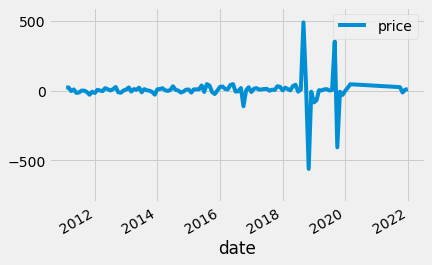

In [16]:
DCTM_Y_diff1 = DCTM_Y.diff(1).dropna()
DCTM_Y_diff1.plot(grid=True)
plt.show()

##### Checking Random Walk

In [17]:
RW_DCTM_Y= adfuller(DCTM_Y_diff1)
RW_DCTM_Y[1] # print P-value. If p-value<5%, reject null hypothesis

0.007797949798797667

##### Plotting ACF and PACF

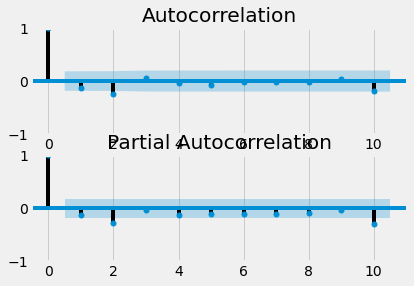

In [18]:
fig, axes=plt.subplots(2,1)
plot_acf(DCTM_Y_diff1, lags=10, ax=axes[0])
plot_pacf(DCTM_Y_diff1, lags=10, ax=axes[1])
plt.show()

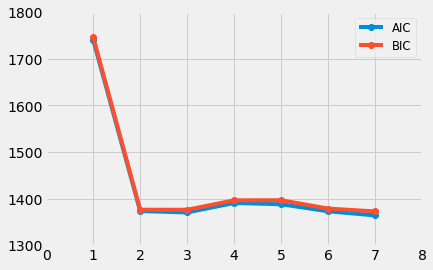

In [19]:
AIC, BIC = AIC_BIC_withOrderRange(DCTM_Y, p=2, d=2, q=2)
# 0:(0,0,0), 1:(0,0,1), 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [20]:
AIC, BIC

(array([1884.33257001, 1740.53920669, 1373.35265882, 1370.41922564,
        1390.66598471, 1387.94735489, 1372.97215188, 1364.0216711 ]),
 array([1887.22291913, 1746.31990495, 1376.23546075, 1376.18482948,
        1396.44668297, 1396.61840228, 1378.73775573, 1372.67007687]))

We will run again 2:(0,1,0), 3:(0,1,1), 4:(1,0,0), 5:(1,0,1), 6:(1,1,0), 7:(1,1,1)

In [21]:
mod_orders = [
    (0,1,0),
    (0,1,1),
    (1,0,0),
    (1,0,1),
    (1,1,0),
    (1,1,1)
]

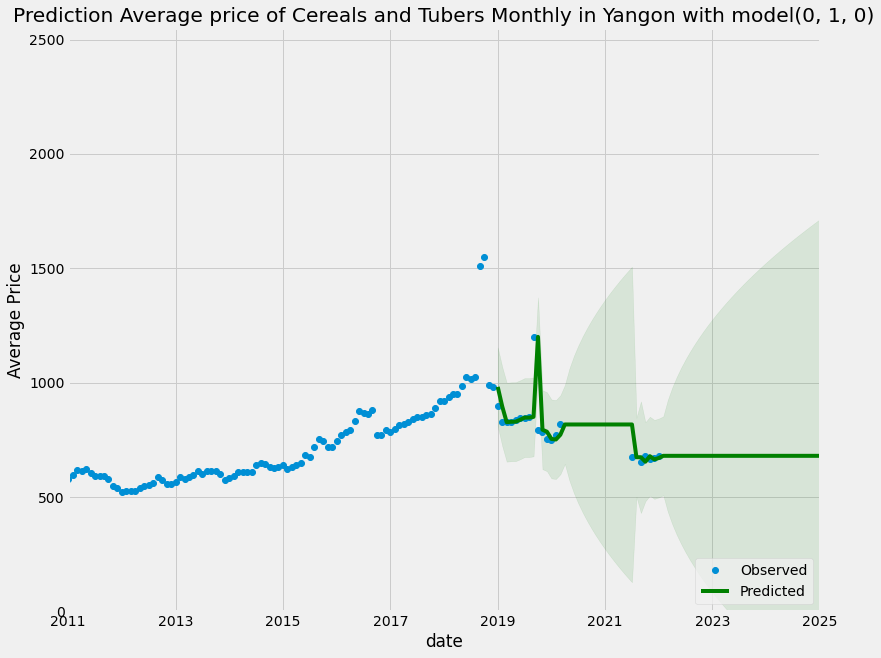

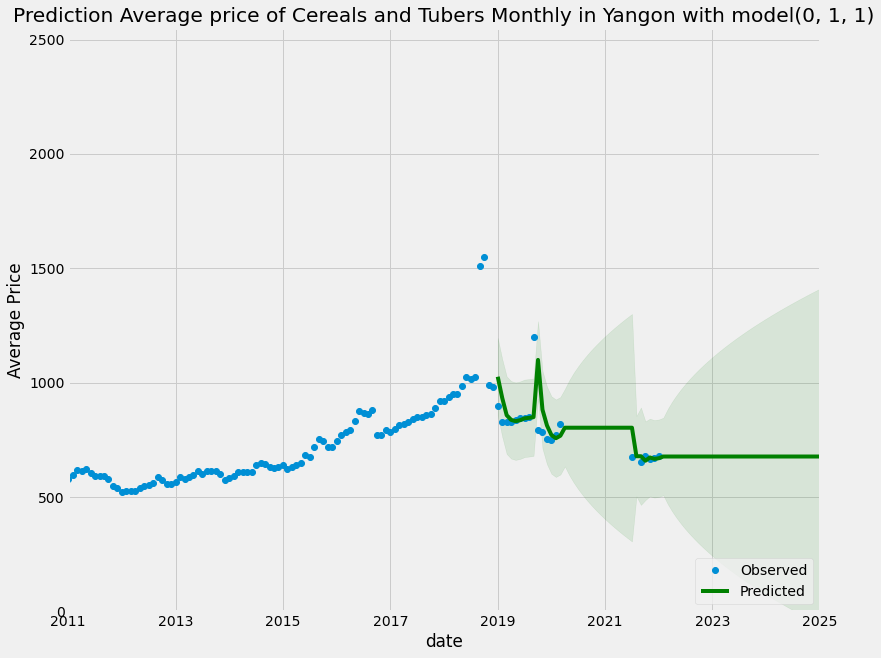

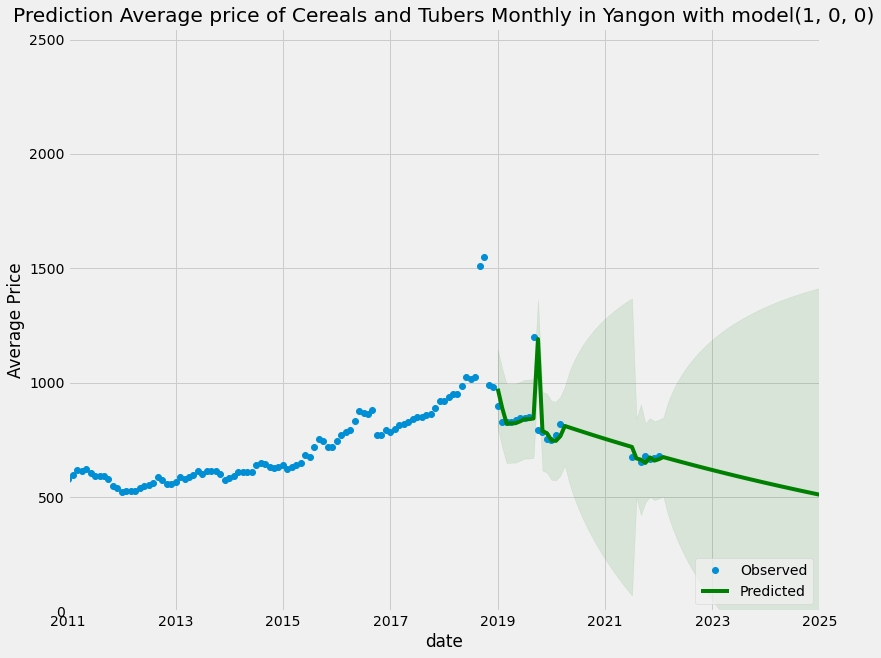

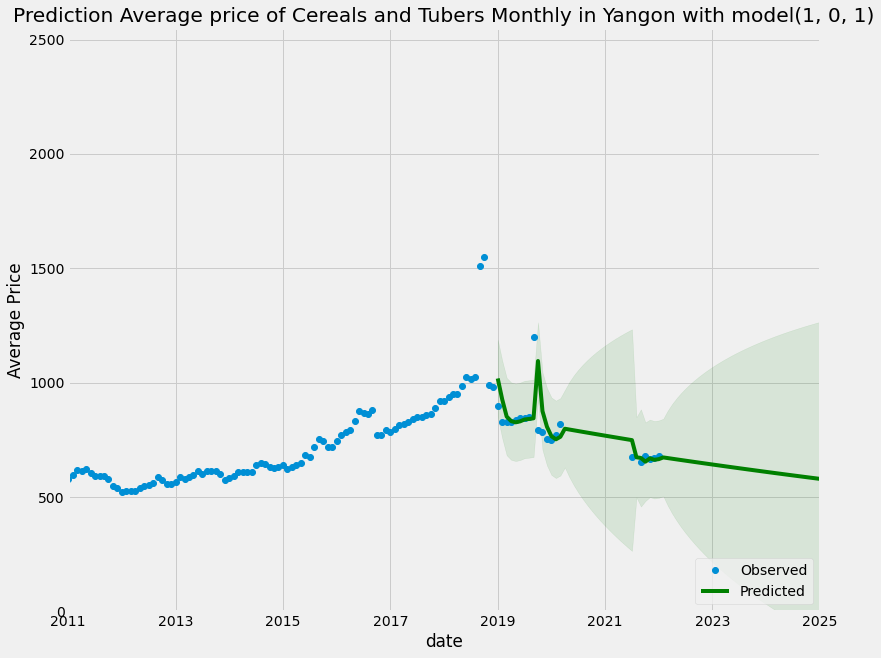

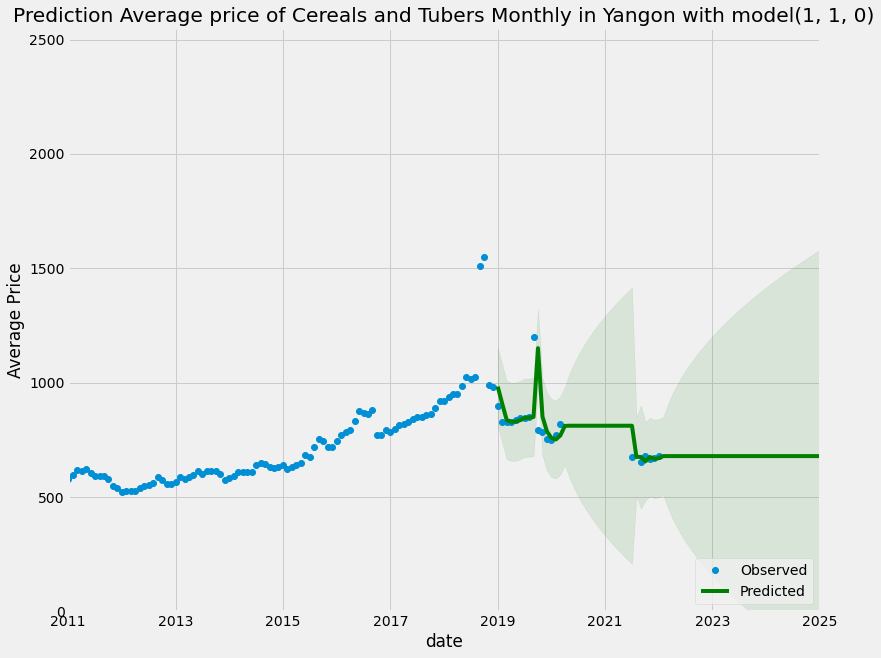

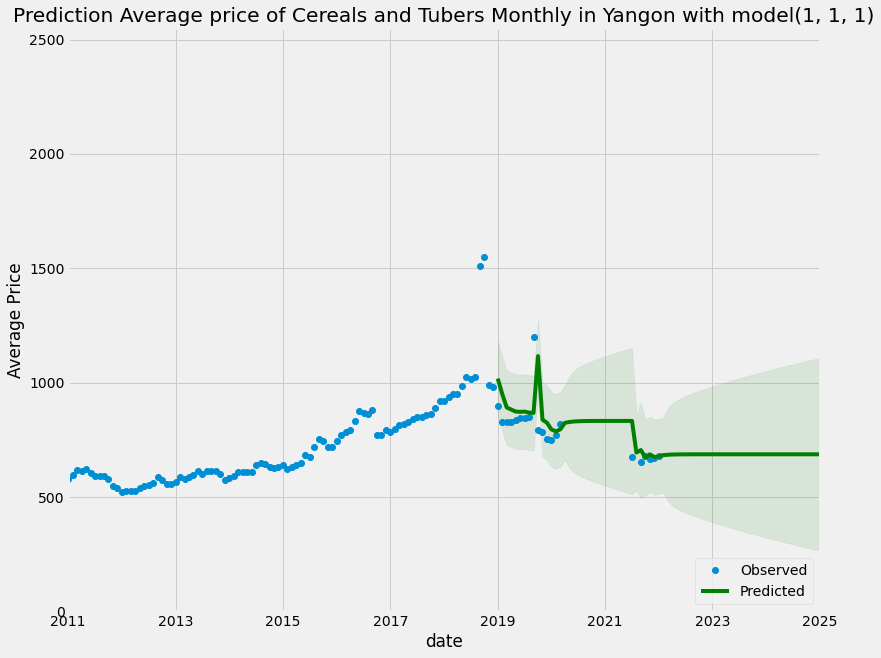

In [22]:
DCTM_Y_models = []
for ind, order in enumerate(mod_orders): 
    model = Run_SARIMAX(DCTM_Y, mod_order=order, time_range=[[obv_st_date, obv_end_date], [pred_st_date, pred_end_date]], col='price', title='Prediction Average price of Cereals and Tubers Monthly in Yangon with model'+str(order), xlabel='Date', ylabel='Average Price')
    DCTM_Y_models.append(model)

Now we choose (1,0,0)

In [23]:
DCTM_Y_model = DCTM_Y_models[2]

In [24]:
DCTM_Y_pred = DCTM_Y_model.predict(pred_st_date, pred_end_date)
DCTM_Y_pred

2019-01-01    973.403306
2019-02-01    888.937027
2019-03-01    820.273764
2019-04-01    822.143738
2019-05-01    822.520709
                 ...    
2024-09-01    526.206184
2024-10-01    522.011607
2024-11-01    517.850466
2024-12-01    513.722496
2025-01-01    509.627431
Freq: MS, Name: predicted_mean, Length: 73, dtype: float64